In [1]:
from pathlib import Path
import copy
import tarfile
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import torch
from scipy.io import loadmat
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
SEQ_LEN = 64
INPUT_SIZE = 91
BATCH_SIZE = 64
HIDDEN_SIZE = 64
MAX_EPOCHS = 50
PATIENCE = 8
DATA_ROOT = Path("/content")
DATA_DIR = DATA_ROOT / "Penn_Action"
LABEL_DIR = DATA_DIR / "labels"
MODEL_PATH = DATA_ROOT / "penn_action_pose_bilstm_91features.pkl"
DATA_URL = "https://www.cis.upenn.edu/~kostas/Penn_Action.tar.gz"

torch.manual_seed(SEED)
np.random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU")

PyTorch: 2.11.0+cpu
Device: CPU


In [2]:
if not LABEL_DIR.exists():
    archive_path = DATA_ROOT / "Penn_Action.tar.gz"
    print("Downloading Penn Action (~3 GB) into this Colab runtime...")
    urllib.request.urlretrieve(DATA_URL, archive_path)
    print("Extracting archive...")
    with tarfile.open(archive_path, "r:gz") as archive:
        archive.extractall(DATA_ROOT, filter="data")
    archive_path.unlink(missing_ok=True)

if not LABEL_DIR.exists():
    raise FileNotFoundError(f"Could not find labels folder: {LABEL_DIR}")

label_files = sorted(LABEL_DIR.glob("*.mat"))
if not label_files:
    raise FileNotFoundError(f"No annotation files found in {LABEL_DIR}")
print("Annotation files:", len(label_files))

Extracting archive...
Annotation files: 2326


In [3]:
base_sequences, actions, official_train = [], [], []

for file_path in label_files:
    item = loadmat(file_path, simplify_cells=True)
    x = np.asarray(item["x"], dtype=np.float32)
    y_coord = np.asarray(item["y"], dtype=np.float32)
    visible = (np.asarray(item["visibility"]) > 0).astype(np.float32)

    dimensions = np.asarray(item["dimensions"]).reshape(-1)
    height, width = float(dimensions[0]), float(dimensions[1])
    x = x / max(width, 1.0) * visible
    y_coord = y_coord / max(height, 1.0) * visible

    # Vectorized resampling to 64 frames.
    positions = np.linspace(0, len(x) - 1, SEQ_LEN)
    left = positions.astype(np.int32)
    right = np.minimum(left + 1, len(x) - 1)
    weight = (positions - left)[:, None]

    x = x[left] * (1 - weight) + x[right] * weight
    y_coord = y_coord[left] * (1 - weight) + y_coord[right] * weight
    visible = visible[left] * (1 - weight) + visible[right] * weight

    coordinates = np.stack((x, y_coord), axis=-1)
    velocity = np.zeros_like(coordinates)
    velocity[1:] = coordinates[1:] - coordinates[:-1]

    base_features = np.concatenate(
        (coordinates.reshape(SEQ_LEN, 26),
         visible.reshape(SEQ_LEN, 13),
         velocity.reshape(SEQ_LEN, 26)),
        axis=1,
    )
    base_sequences.append(base_features.astype(np.float32))
    actions.append(str(item["action"]))
    official_train.append(int(item["train"]))

X_base = np.asarray(base_sequences, dtype=np.float32)
action_names = sorted(set(actions))
action_to_id = {name: i for i, name in enumerate(action_names)}
y_all = np.asarray([action_to_id[name] for name in actions], dtype=np.int64)
official_train = np.asarray(official_train) == 1

# Add parent-relative bone vectors to the 65 existing features.
n_clips = len(X_base)
coordinates = X_base[:, :, :26].reshape(n_clips, SEQ_LEN, 13, 2)
visibility = X_base[:, :, 26:39]

torso_joints = [1, 2, 7, 8]
torso_weights = visibility[:, :, torso_joints, None]
torso_center = (
    (coordinates[:, :, torso_joints, :] * torso_weights).sum(axis=2)
    / (torso_weights.sum(axis=2) + 1e-8)
)

parents = [-1, -1, -1, 1, 2, 3, 4, -1, -1, 7, 8, 9, 10]
bones = np.zeros_like(coordinates)
for joint, parent in enumerate(parents):
    if parent == -1:
        bones[:, :, joint, :] = coordinates[:, :, joint, :] - torso_center
        bones[:, :, joint, :] *= visibility[:, :, joint, None]
    else:
        bones[:, :, joint, :] = coordinates[:, :, joint, :] - coordinates[:, :, parent, :]
        bones[:, :, joint, :] *= (
            visibility[:, :, joint] * visibility[:, :, parent]
        )[:, :, None]

X_all = np.concatenate(
    [X_base, bones.reshape(n_clips, SEQ_LEN, 26)],
    axis=2,
).astype(np.float32)

assert X_all.shape[1:] == (SEQ_LEN, INPUT_SIZE), (
    f"Expected (clips, {SEQ_LEN}, {INPUT_SIZE}), got {X_all.shape}"
)

X_train_all, y_train_all = X_all[official_train], y_all[official_train]
X_test, y_test = X_all[~official_train], y_all[~official_train]
print("Features:", X_all.shape, "| Train:", len(X_train_all), "| Test:", len(X_test))
print("Actions:", action_names)

Features: (2326, 64, 91) | Train: 1258 | Test: 1068
Actions: ['baseball_pitch', 'baseball_swing', 'bench_press', 'bowl', 'clean_and_jerk', 'golf_swing', 'jump_rope', 'jumping_jacks', 'pullup', 'pushup', 'situp', 'squat', 'strum_guitar', 'tennis_forehand', 'tennis_serve']


In [4]:
train_idx, val_idx = train_test_split(
    np.arange(len(X_train_all)),
    test_size=0.2,
    random_state=SEED,
    stratify=y_train_all,
)

mean = X_train_all[train_idx].mean(axis=(0, 1), keepdims=True)
std = X_train_all[train_idx].std(axis=(0, 1), keepdims=True) + 1e-8
X_train_scaled = np.ascontiguousarray((X_train_all - mean) / std, dtype=np.float32)
X_test_scaled = np.ascontiguousarray((X_test - mean) / std, dtype=np.float32)

train_data = TensorDataset(
    torch.from_numpy(X_train_scaled[train_idx]),
    torch.from_numpy(y_train_all[train_idx]),
)
val_data = TensorDataset(
    torch.from_numpy(X_train_scaled[val_idx]),
    torch.from_numpy(y_train_all[val_idx]),
)
test_data = TensorDataset(torch.from_numpy(X_test_scaled), torch.from_numpy(y_test))

pin_memory = device.type == "cuda"
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, pin_memory=pin_memory)
val_loader = DataLoader(val_data, batch_size=128, shuffle=False, pin_memory=pin_memory)
test_loader = DataLoader(test_data, batch_size=128, shuffle=False, pin_memory=pin_memory)
print("Train batches:", len(train_loader), "| Validation batches:", len(val_loader))

Train batches: 16 | Validation batches: 2


In [5]:
class PoseMotionBiLSTM(nn.Module):
    def __init__(self, input_size=91, hidden_size=64, num_classes=15):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=2,
            batch_first=True,
            bidirectional=True,
            dropout=0.3,
        )
        self.classifier = nn.Linear(hidden_size * 2, num_classes)

    def forward(self, x):
        _, (hidden, _) = self.lstm(x)
        final_state = torch.cat((hidden[-2], hidden[-1]), dim=1)
        return self.classifier(final_state)


input_dim = X_train_scaled.shape[-1]
assert input_dim == INPUT_SIZE == 91
model = PoseMotionBiLSTM(
    input_size=input_dim,
    hidden_size=HIDDEN_SIZE,
    num_classes=len(action_names),
).to(device)
print("Model input features:", model.lstm.input_size)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)

best_val_accuracy = 0.0
best_state = None
epochs_without_improvement = 0

for epoch in range(MAX_EPOCHS):
    model.train()
    total_loss = 0.0
    for xb, yb in train_loader:
        xb = xb.to(device, non_blocking=pin_memory)
        yb = yb.to(device, non_blocking=pin_memory)
        optimizer.zero_grad(set_to_none=True)
        loss = loss_fn(model(xb), yb)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    model.eval()
    correct = total = 0
    with torch.inference_mode():
        for xb, yb in val_loader:
            logits = model(xb.to(device, non_blocking=pin_memory))
            correct += (logits.argmax(dim=1).cpu() == yb).sum().item()
            total += len(yb)

    val_accuracy = correct / total
    print(f"Epoch {epoch + 1}: loss={total_loss / len(train_loader):.4f}, val_acc={val_accuracy * 100:.2f}%")

    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        best_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= PATIENCE:
            print("Early stopping.")
            break

if best_state is None:
    raise RuntimeError("Training did not produce a valid model checkpoint.")
model.load_state_dict(best_state)
print(f"Best validation accuracy: {best_val_accuracy * 100:.2f}%")

Model input features: 91
Epoch 1: loss=2.5866, val_acc=50.00%
Epoch 2: loss=2.0507, val_acc=57.14%
Epoch 3: loss=1.3175, val_acc=71.83%
Epoch 4: loss=0.7782, val_acc=80.56%
Epoch 5: loss=0.4796, val_acc=86.90%
Epoch 6: loss=0.3060, val_acc=88.49%
Epoch 7: loss=0.2072, val_acc=88.10%
Epoch 8: loss=0.1332, val_acc=91.27%
Epoch 9: loss=0.0938, val_acc=92.06%
Epoch 10: loss=0.0712, val_acc=90.87%
Epoch 11: loss=0.0659, val_acc=92.46%
Epoch 12: loss=0.0492, val_acc=93.25%
Epoch 13: loss=0.0382, val_acc=92.86%
Epoch 14: loss=0.0291, val_acc=93.25%
Epoch 15: loss=0.0207, val_acc=93.65%
Epoch 16: loss=0.0165, val_acc=94.05%
Epoch 17: loss=0.0143, val_acc=93.25%
Epoch 18: loss=0.0122, val_acc=93.25%
Epoch 19: loss=0.0107, val_acc=93.25%
Epoch 20: loss=0.0094, val_acc=93.65%
Epoch 21: loss=0.0085, val_acc=93.25%
Epoch 22: loss=0.0075, val_acc=93.25%
Epoch 23: loss=0.0071, val_acc=93.65%
Epoch 24: loss=0.0065, val_acc=92.86%
Early stopping.
Best validation accuracy: 94.05%


## 5. Evaluate on the official test split

Test accuracy: 90.92%
                 precision    recall  f1-score   support

 baseball_pitch       0.88      0.95      0.92        63
 baseball_swing       0.75      0.95      0.84        58
    bench_press       0.96      0.97      0.97        71
           bowl       0.95      0.88      0.91        85
 clean_and_jerk       0.96      0.98      0.97        45
     golf_swing       0.91      0.96      0.94        77
      jump_rope       0.90      0.83      0.86        42
  jumping_jacks       0.98      0.91      0.94        56
         pullup       0.97      0.96      0.97       101
         pushup       0.98      0.96      0.97       107
          situp       0.96      0.92      0.94        50
          squat       0.94      0.91      0.92       117
   strum_guitar       0.96      0.98      0.97        48
tennis_forehand       0.74      0.65      0.69        77
   tennis_serve       0.79      0.83      0.81        71

       accuracy                           0.91      1068
      m

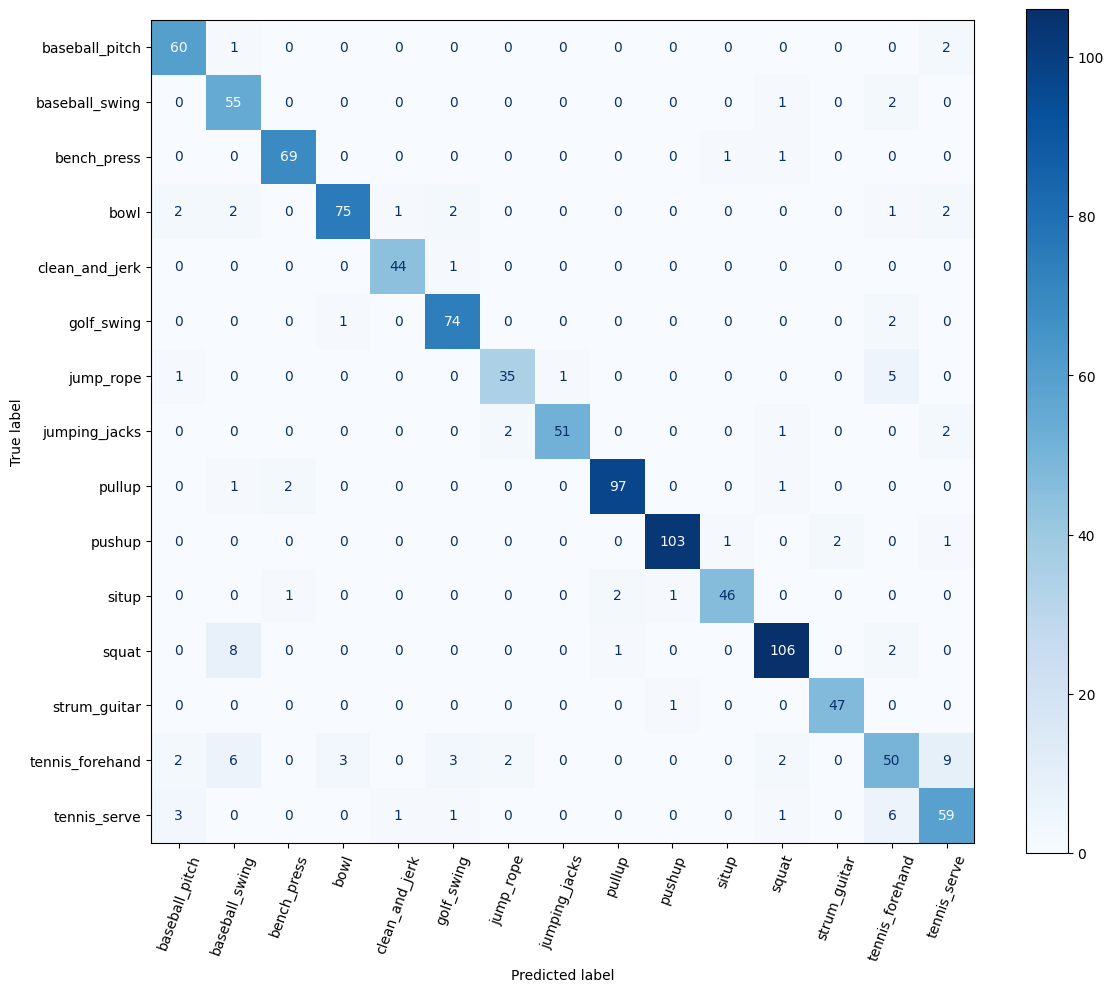

In [6]:
model.eval()
all_predictions, all_labels = [], []
with torch.inference_mode():
    for xb, yb in test_loader:
        logits = model(xb.to(device, non_blocking=pin_memory))
        all_predictions.extend(logits.argmax(dim=1).cpu().numpy())
        all_labels.extend(yb.numpy())

test_accuracy = float(np.mean(np.asarray(all_predictions) == np.asarray(all_labels)))
print(f"Test accuracy: {test_accuracy * 100:.2f}%")
print(classification_report(
    all_labels,
    all_predictions,
    labels=list(range(len(action_names))),
    target_names=action_names,
    zero_division=0,
))

fig, ax = plt.subplots(figsize=(12, 10))
ConfusionMatrixDisplay.from_predictions(
    all_labels,
    all_predictions,
    labels=list(range(len(action_names))),
    display_labels=action_names,
    xticks_rotation=70,
    cmap="Blues",
    ax=ax,
)
fig.tight_layout()
plt.show()

In [8]:
torch.save({
    "model_state_dict": {key: value.detach().cpu() for key, value in model.state_dict().items()},
    "input_size": model.lstm.input_size,
    "hidden_size": HIDDEN_SIZE,
    "num_classes": len(action_names),
    "mean": torch.from_numpy(mean),
    "std": torch.from_numpy(std),
    "action_names": action_names,
    "test_accuracy": test_accuracy,
}, MODEL_PATH)

print("Saved:", MODEL_PATH)
from google.colab import files
files.download(str(MODEL_PATH))

Saved: /content/penn_action_pose_bilstm_91features.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>